# Artificial Intelligence in Health Care

# NB3: Building a CNN
### Why convolution beats a dense network, with fewer parameters

In the lecture we argued that a dense network is the wrong tool for an image. This
notebook makes that argument with numbers.

**Dataset BloodMNIST:** 8 classes of peripheral blood cell microscopy, 28×28
RGB. 

Everything should run at native 28×28 on CPU.

In [1]:
import os
os.environ["KERAS_BACKEND"] = "torch"

import warnings
import numpy as np
import matplotlib.pyplot as plt
import keras
from keras import layers
from sklearn.metrics import accuracy_score, roc_auc_score, confusion_matrix

warnings.filterwarnings("ignore")
SEED = 42
keras.utils.set_random_seed(SEED)
plt.rcParams.update({"figure.dpi": 110, "font.size": 9,
                     "axes.grid": True, "grid.alpha": 0.3})
print("keras", keras.__version__, "| backend", keras.backend.backend())

keras 3.15.1 | backend torch


---
## 1 The data

BloodMNIST comes from a study of ~17,000 peripheral blood cell images from healthy
donors. Eight cell types which is similar to the sort of classification a haematology analyser does
routinely.

In [2]:
from medmnist import BloodMNIST
from medmnist import INFO

info = INFO["bloodmnist"]
CLASSES = [v.split(",")[0] for v in info["label"].values()]

tr = BloodMNIST(split="train", download=True)
va = BloodMNIST(split="val",   download=True)
te = BloodMNIST(split="test",  download=True)

Xtr = tr.imgs.astype("float32") / 255.0     # (N, 28, 28, 3), scaled to [0, 1]
Xva = va.imgs.astype("float32") / 255.0
Xte = te.imgs.astype("float32") / 255.0
ytr = tr.labels.ravel(); yva = va.labels.ravel(); yte = te.labels.ravel()

print("train / val / test:", len(ytr), len(yva), len(yte))
print("image shape       :", Xtr.shape[1:])
print("classes           :", len(CLASSES))
for i, c in enumerate(CLASSES):
    print(f"  {i}  {c:<28} {100*(ytr==i).mean():>5.1f}%")
print()
print("majority-class baseline accuracy: %.3f" % (np.bincount(yte).max()/len(yte)))

train / val / test: 11959 1712 3421
image shape       : (28, 28, 3)
classes           : 8
  0  basophil                       7.1%
  1  eosinophil                    18.2%
  2  erythroblast                   9.1%
  3  immature granulocytes(myelocytes  16.9%
  4  lymphocyte                     7.1%
  5  monocyte                       8.3%
  6  neutrophil                    19.5%
  7  platelet                      13.7%

majority-class baseline accuracy: 0.195


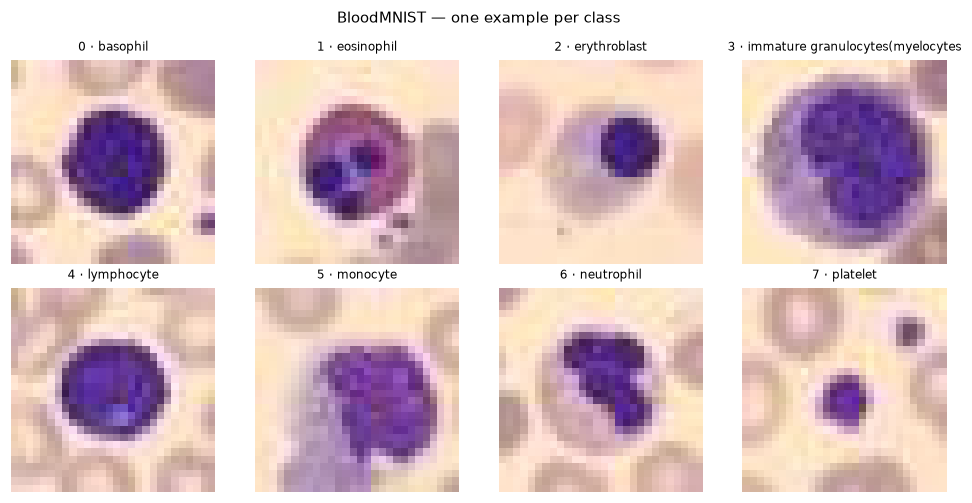

In [3]:
fig, axes = plt.subplots(2, 4, figsize=(9, 4.6))
for i, ax in enumerate(axes.ravel()):
    ax.imshow(Xtr[np.where(ytr == i)[0][0]])
    ax.set_title(f"{i} · {CLASSES[i]}", fontsize=8)
    ax.axis("off")
fig.suptitle("BloodMNIST — one example per class", fontsize=10)
plt.tight_layout(); plt.show()

Look at them for a moment. At 28×28 you can see colour and rough shape (the
purple of a stained nucleus, how much of the cell it occupies). You cannot see
chromatin texture or granule detail, which is part of what a haematologist uses.

This resolution supports an exercise
about architecture, not a clinical claim.

---
## 2 A dense baseline

Architecture: Flatten the image into a long
vector of numbers, then a stack of `Dense` layers.

**Flattening throws away the geometry.** Pixel (3, 4) and pixel (3, 5) are
neighbours in the image and become two unrelated positions in a vector of 2,352.
The network has to rediscover adjacency from scratch, from data.

In [ ]:
def train_model(model, epochs=25, tag=""):
    model.compile(optimizer=keras.optimizers.Adam(1e-3),
                  loss=keras.losses.SparseCategoricalCrossentropy(from_logits=True),
                  metrics=[keras.metrics.SparseCategoricalAccuracy(name="acc")])
    
    es = keras.callbacks.EarlyStopping(monitor="val_acc", mode="max",
                                       patience=5, restore_best_weights=True)
    
    h = model.fit(Xtr, ytr, validation_data=(Xva, yva), epochs=epochs,
                  batch_size=128, verbose=0, callbacks=[es])
    
    logits = model.predict(Xte, verbose=0)
    prob = keras.ops.softmax(logits).numpy() if hasattr(keras, "ops") else logits
    pred = prob.argmax(1) # argmax along the class dimension for each sample
    
    acc = accuracy_score(yte, pred)
    auc = roc_auc_score(yte, prob, multi_class="ovr", average="macro")
    n_par = model.count_params()
    print(f"{tag:<22} test accuracy {acc:.4f}   macro AUROC {auc:.4f}   "
          f"parameters {n_par:,}   epochs {len(h.history['loss'])}")
    return dict(tag=tag, model=model, hist=h, acc=acc, auc=auc, params=n_par,
                prob=prob, pred=pred)


keras.utils.set_random_seed(SEED)
dense = keras.Sequential([
    layers.Input(shape=(28, 28, 3)),
    layers.Flatten(),                      # 28*28*3 = 2352 numbers, geometry gone
    layers.Dense(1024, activation="relu"),
    layers.Dropout(0.3),
    layers.Dense(512, activation="relu"),
    layers.Dropout(0.3),
    layers.Dense(128, activation="relu"),
    layers.Dense(len(CLASSES)),            # logits
], name="dense")

res_dense = train_model(dense, tag="dense network")

dense network          test accuracy 0.7422   macro AUROC 0.9523   parameters 3,000,968   epochs 12


---
## 3 A basic CNN

The same job, built the way the lecture described it:

- **`Conv2D`:** a small filter slides over the image; the same weights are used
  at every position. An edge detector that works in the corner works in the
  middle too, and you only pay for it once.
- **`MaxPooling2D`:** halve the resolution, keep the strongest response. The
  next layer's filters then cover a larger area of the original image.
- Repeat, then **`Flatten`** and finish with a small dense head.

### What do you expect?

The dense network above has over two million parameters. The CNN below will have
far fewer.

**Will it do better or worse?** 

In [5]:
keras.utils.set_random_seed(SEED)
cnn = keras.Sequential([
    layers.Input(shape=(28, 28, 3)),

    layers.Conv2D(32, 3, activation="relu", padding="same"), # Convolutional layer with 32 filters of size 3x3
    layers.Conv2D(32, 3, activation="relu", padding="same"),
    layers.MaxPooling2D(2),                # 28x28 -> 14x14

    layers.Conv2D(64, 3, activation="relu", padding="same"), # Convolutional layer with 64 filters of size 3x3
    layers.Conv2D(64, 3, activation="relu", padding="same"),
    layers.MaxPooling2D(2),                # 14x14 -> 7x7

    layers.Flatten(),
    layers.Dropout(0.3),
    layers.Dense(128, activation="relu"),
    layers.Dense(len(CLASSES)),            # logits
], name="cnn")

cnn.summary()

Model: "cnn"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 28, 28, 32)     │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 28, 28, 32)     │         9,248 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 14, 14, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 14, 14, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 14, 14, 64)     │        36,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 7, 7, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_1 (Flatten)             │ (None, 3136)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 3136)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 128)            │       401,536 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 8)              │         1,032 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 468,136 (1.79 MB)

 Trainable params: 468,136 (1.79 MB)

 Non-trainable params: 0 (0.00 B)

In [6]:
res_cnn = train_model(cnn, tag="convolutional network")

convolutional network  test accuracy 0.9369   macro AUROC 0.9943   parameters 468,136   epochs 23


---
## 4 The comparison that matters

Accuracy alone understates the result. Put the parameter count beside it.

In [7]:
print(f"{'model':<24}{'test acc':>10}{'macro AUROC':>14}{'parameters':>14}")
print("-" * 62)
for r in (res_dense, res_cnn):
    print(f"{r['tag']:<24}{r['acc']:>10.4f}{r['auc']:>14.4f}{r['params']:>14,}")

ratio = res_dense["params"] / res_cnn["params"]
print()
print(f"the CNN uses {ratio:.1f}x fewer parameters")
print(f"accuracy difference: {res_cnn['acc'] - res_dense['acc']:+.4f}")

model                     test acc   macro AUROC    parameters
--------------------------------------------------------------
dense network               0.7422        0.9523     3,000,968
convolutional network       0.9369        0.9943       468,136

the CNN uses 6.4x fewer parameters
accuracy difference: +0.1947


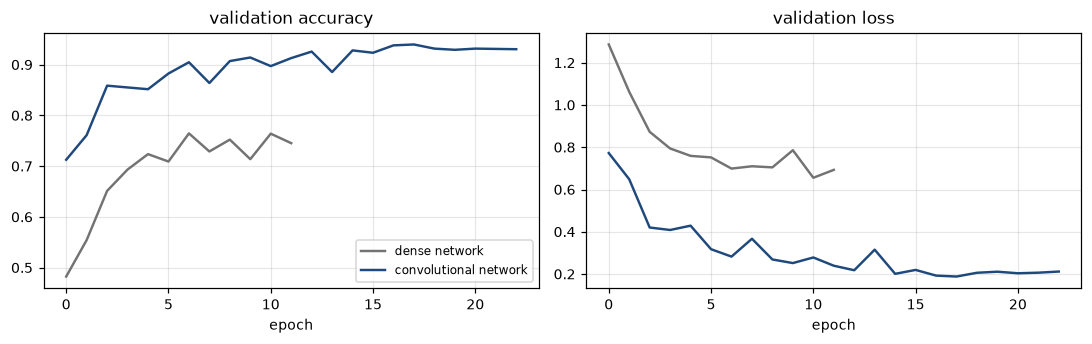

In [8]:
fig, ax = plt.subplots(1, 2, figsize=(10, 3.2))
for r, col in [(res_dense, "0.45"), (res_cnn, "#1f497d")]:
    ax[0].plot(r["hist"].history["val_acc"], color=col, lw=1.6, label=r["tag"])
    ax[1].plot(r["hist"].history["val_loss"], color=col, lw=1.6, label=r["tag"])
ax[0].set_title("validation accuracy"); ax[0].set_xlabel("epoch")
ax[1].set_title("validation loss");     ax[1].set_xlabel("epoch")
ax[0].legend(fontsize=8); plt.tight_layout(); plt.show()

### Why the CNN wins with less

Three things, all consequences of the same design choice:

1. **Weight sharing.** One filter is reused at every position. A dense layer
   learns a separate weight for every pixel *and* every unit.
2. **Locality.** A filter looks at a small neighbourhood, which is where the
   information in an image actually lives.
3. **Spatial invariance.** A cell slightly off-centre still activates the same
   filters. The dense network would have to learn that case separately.

The dense network is not incapable, it is *spending its capacity badly*. Given
enough data it can approximate what the CNN does, but it has to learn from
scratch what convolution builds in for free.



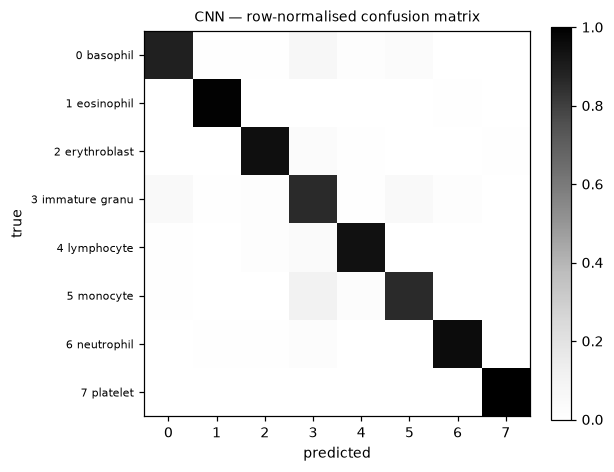

weakest class: 3 · immature granulocytes(myelocytes  (recall 0.857)
most often confused with: monocyte


In [9]:
cm = confusion_matrix(yte, res_cnn["pred"])
fig, ax = plt.subplots(figsize=(5.4, 4.6))
im = ax.imshow(cm / cm.sum(1, keepdims=True), cmap="Greys", vmin=0, vmax=1)
ax.set_xticks(range(len(CLASSES))); ax.set_yticks(range(len(CLASSES)))
ax.set_xticklabels(range(len(CLASSES))); ax.set_yticklabels(
    [f"{i} {c[:14]}" for i, c in enumerate(CLASSES)], fontsize=7)
ax.set_xlabel("predicted"); ax.set_ylabel("true")
ax.set_title("CNN — row-normalised confusion matrix", fontsize=9)
ax.grid(False); plt.colorbar(im, fraction=0.046); plt.tight_layout(); plt.show()

per_class = cm.diagonal() / cm.sum(1)
worst = per_class.argmin()
print(f"weakest class: {worst} · {CLASSES[worst]}  (recall {per_class[worst]:.3f})")
print(f"most often confused with: {CLASSES[np.argsort(cm[worst])[-2]]}")

A confusion matrix says more than a single accuracy. Look at which classes get
mixed up. Cell types that look alike under a microscope also look alike to the
network, which is at least a sane failure mode.


---
## 5 What the filters learned

The first convolutional layer produces 32 feature maps per image. Each is the
response of one filter, at every position.

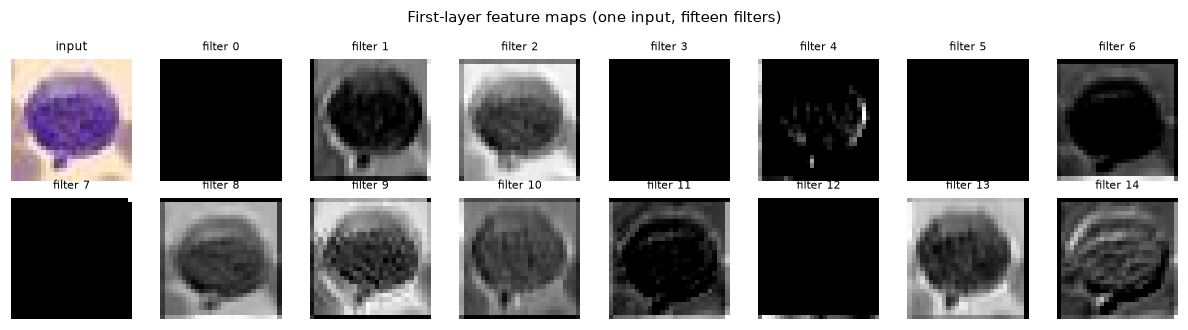

In [10]:
probe = keras.Model(cnn.inputs, cnn.layers[0].output)
img = Xte[0:1]
maps = probe.predict(img, verbose=0)[0]        # (28, 28, 32)

fig, axes = plt.subplots(2, 8, figsize=(11, 3.0))
axes[0, 0].imshow(img[0]); axes[0, 0].set_title("input", fontsize=8)
axes[0, 0].axis("off")
for k, ax in enumerate(axes.ravel()[1:16]):
    ax.imshow(maps[:, :, k], cmap="gray")
    ax.set_title(f"filter {k}", fontsize=7); ax.axis("off")
fig.suptitle("First-layer feature maps (one input, fifteen filters)", fontsize=10)
plt.tight_layout(); plt.show()

Some filters brighten at the cell boundary, some respond to the stained nucleus,
some appear to do very little. Nobody specified any of this, it was learned by
minimising the loss.

This is the hierarchy from Session 4: **edges and colour blobs early, structure
later.** It is also the reason transfer learning works at all.

**Note:** A feature map is not an explanation. It shows what
a filter responded to, not why the model decided what it decided. We will make
that distinction sharply when we get to interpretability.

---
## 6 Pushing further

Everything so far stays at the native **28×28**. That is a deliberate choice, and
it rules one popular option out.

### Why there is no pretrained backbone in this notebook

Pretrained ImageNet models (ResNet, MobileNet, EfficientNet) expect inputs of at
least 32×32, and are trained at 224×224. To use one here you must **upsample
28×28 to 224×224, which invents no additional information.** It stretches what is
already there, then runs a very large model over the result. It is slow, and on
small low-resolution medical images it frequently loses to a small CNN trained
from scratch. See Raghu et al. (2019) https://doi.org/10.48550/arXiv.1902.07208 for detailed information.

Transfer learning is still allowed in the UE2 challenge, and it is worth trying.

**Some things worth trying at 28×28.** Worth *trying*, but not guaranteed to help.
We will measure all them against the plain CNN above, and you should be ready
for the answer to be "no".

### 6a Data augmentation

Free extra training data (as long as each transformation is one the microscope
could genuinely have produced).

Blood smears have **no specific orientation**: the cell could have landed on the
slide any way round. So flips and rotations are physically valid here. E.g. on a chest
radiograph a horizontal flip would not be valid because it destroys left from right.

In [11]:
augment = keras.Sequential([
    layers.RandomFlip("horizontal_and_vertical"),   # valid: no canonical orientation
    layers.RandomRotation(0.15),                    # valid: same reason
    layers.RandomZoom(0.1),                         # valid: focus/magnification varies
], name="augment")

keras.utils.set_random_seed(SEED)
cnn_aug = keras.Sequential([
    layers.Input(shape=(28, 28, 3)),
    augment,                                   # active in fit(), inert in predict()
    layers.Conv2D(32, 3, activation="relu", padding="same"),
    layers.Conv2D(32, 3, activation="relu", padding="same"),
    layers.MaxPooling2D(2),
    layers.Conv2D(64, 3, activation="relu", padding="same"),
    layers.Conv2D(64, 3, activation="relu", padding="same"),
    layers.MaxPooling2D(2),
    layers.Flatten(),
    layers.Dropout(0.3),
    layers.Dense(128, activation="relu"),
    layers.Dense(len(CLASSES)),
], name="cnn_augmented")

res_aug = train_model(cnn_aug, epochs=30, tag="CNN + augmentation")

CNN + augmentation     test accuracy 0.9076   macro AUROC 0.9926   parameters 468,136   epochs 21


### 6b Batch normalisation

Normalises activations between layers. In practice it lets you train deeper
stacks, and train them faster.

In [12]:
# slightly other way to implement a network by defining a function for a 
# block of layers, then calling it multiple times
# Note: x is going to be transformed by the layers, so we need to return it 
# at the end of the function and use it as the input for the next layer and so on.
def conv_block(x, n):
    x = layers.Conv2D(n, 3, padding="same", use_bias=False)(x)
    x = layers.BatchNormalization()(x)
    x = layers.Activation("relu")(x)
    x = layers.Conv2D(n, 3, padding="same", use_bias=False)(x)
    x = layers.BatchNormalization()(x)
    x = layers.Activation("relu")(x)
    return layers.MaxPooling2D(2)(x)


keras.utils.set_random_seed(SEED)
inp = layers.Input(shape=(28, 28, 3))
z = augment(inp)
z = conv_block(z, 32)                     # 28 -> 14
z = conv_block(z, 64)                     # 14 -> 7
z = conv_block(z, 128)                    # 7  -> 3
z = layers.GlobalAveragePooling2D()(z)    # no huge Flatten -> far fewer parameters
z = layers.Dropout(0.3)(z)
out = layers.Dense(len(CLASSES))(z)
cnn_deep = keras.Model(inp, out, name="cnn_deep")

res_deep = train_model(cnn_deep, epochs=30, tag="deeper CNN + BN + aug")

deeper CNN + BN + aug  test accuracy 0.8600   macro AUROC 0.9916   parameters 289,384   epochs 11


Note `GlobalAveragePooling2D` in place of `Flatten`. Flattening a 3×3×128 feature
map into a dense layer costs thousands of weights; global average pooling
collapses each feature map to a single number and costs none. It is one of the
cheapest parameter savings available.

In [13]:
print(f"{'model':<26}{'test acc':>10}{'macro AUROC':>14}{'parameters':>14}")
print("-" * 64)
for r in (res_dense, res_cnn, res_aug, res_deep):
    print(f"{r['tag']:<26}{r['acc']:>10.4f}{r['auc']:>14.4f}{r['params']:>14,}")

model                       test acc   macro AUROC    parameters
----------------------------------------------------------------
dense network                 0.7422        0.9523     3,000,968
convolutional network         0.9369        0.9943       468,136
CNN + augmentation            0.9076        0.9926       468,136
deeper CNN + BN + aug         0.8600        0.9916       289,384


### Read this table honestly

**Neither "improvement" improved anything.** The plain CNN from §3 is still the
best model in the table: augmentation cost about 3 accuracy points, and the
deeper batch-normalised network cost about 8. Macro AUROC barely moved in either
case, which tells you the ranking of the classes is stable.

That is a real result, and it is the reason this section exists. Two things
plausibly explain it, and you can check both:

- **The training set is already large enough.** ~12,000 images for 8 classes at
  28×28 is not the small-data regime where augmentation pays. Augmentation buys
  invariance you have to pay for in fitting effort.
- **Early stopping fired early.** Look at the epoch counts: the plain CNN trained
  for 23 epochs, the deeper one stopped after 11. Augmented training curves are
  noisier, so `patience=5` on validation accuracy can stop a model that was still
  improving. Raising the patience is the first thing to try before concluding
  that batch normalisation "does not work".

Note also that the deeper network reached its result with **fewer parameters**
than the plain CNN (that is `GlobalAveragePooling2D` doing its job). 